# Food Image Classifier

TME 6015 Assignment 2. The task is to classify recipe blog photos into six classes: cake, cookies, pasta, salad, soup and stir_fry.

The notebook trains two models on the same data:

1. **Model 1:** a CNN built from scratch. It starts from a standard baseline, and each change after that is tested on the validation set.
2. **Model 2:** transfer learning from a pre-trained backbone.

## 1. Setup

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, classification_report, f1_score
from tensorflow.keras import layers

In [2]:
ROOT = Path.cwd()  # the notebook runs from the repo root
SPLIT = ROOT / "data" / "split"
CLASS_NAMES = ["cake", "cookies", "pasta", "salad", "soup", "stir_fry"]
NUM_CLASSES = len(CLASS_NAMES)
IMG_SIZE = (224, 224)
INPUT_SHAPE = IMG_SIZE + (3,)
BATCH_SIZE = 32
SEED = 42

tf.keras.utils.set_random_seed(SEED)

## 2. Data

### 2.1 Loading

The split script wrote one folder per class inside `train/`, `val/` and `test/`.

In [3]:
def load(split, training=False):
    ds = tf.keras.utils.image_dataset_from_directory(
        SPLIT / split,
        class_names=CLASS_NAMES,
        label_mode="int",
        image_size=IMG_SIZE,
        crop_to_aspect_ratio=True,
        batch_size=None,
        shuffle=False,
    )
    files = ds.file_paths
    ds = ds.cache()
    if training:
        ds = ds.shuffle(len(files), seed=SEED)
    return ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE), files


train_ds, train_files = load("train", training=True)
val_ds, val_files = load("val")
test_ds, test_files = load("test")

train_ds.element_spec

Found 1175 files belonging to 6 classes.
Found 252 files belonging to 6 classes.
Found 252 files belonging to 6 classes.


(TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None),
 TensorSpec(shape=(None,), dtype=tf.int32, name=None))

### 2.2 Sanity check

One batch of training images with their labels. This confirms that the labels match the images and that the centre crop keeps the food in frame.

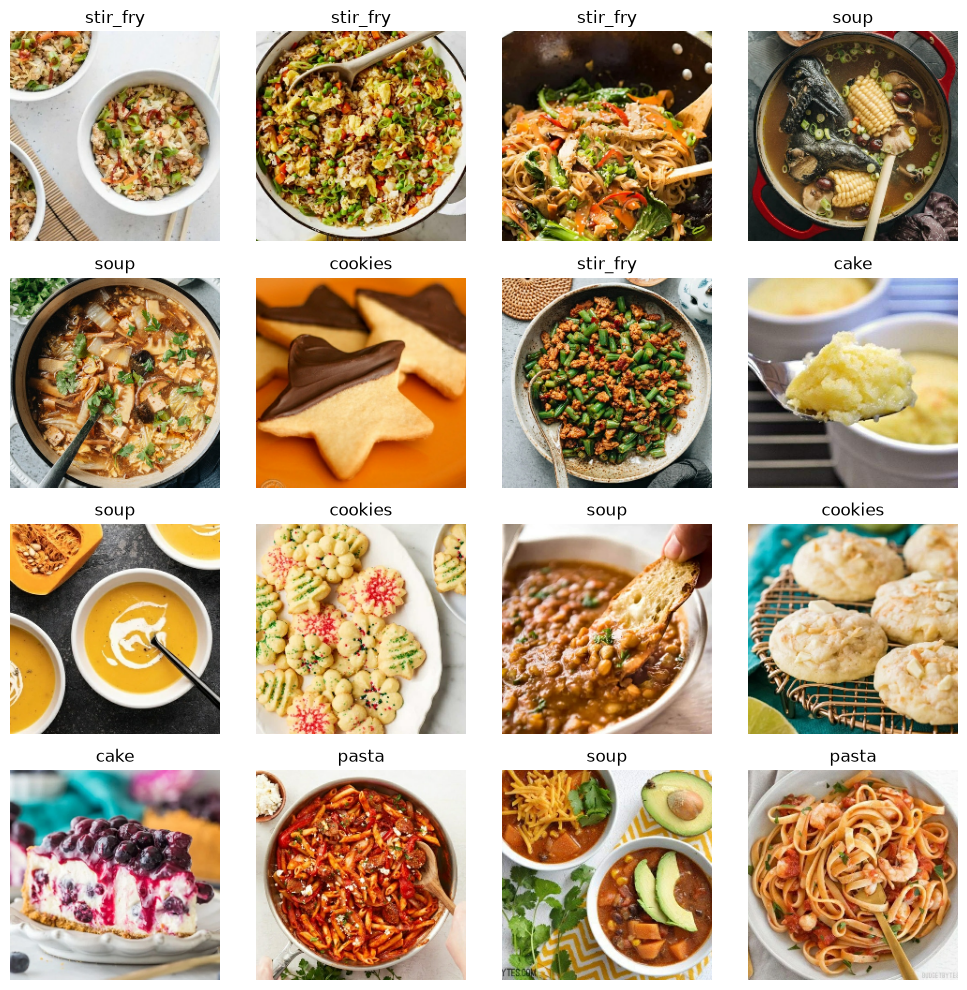

In [4]:
def show_images(images, titles, cols=4):
    rows = int(np.ceil(len(titles) / cols))
    plt.figure(figsize=(2.5 * cols, 2.5 * rows))
    for i, title in enumerate(titles):
        plt.subplot(rows, cols, i + 1)
        plt.imshow(np.asarray(images[i]).astype("uint8"))
        plt.title(title)
        plt.axis("off")
    plt.tight_layout()
    plt.show()


images, labels = next(iter(train_ds))
show_images(images, [CLASS_NAMES[i] for i in labels[:16]])

### 2.3 Class weights

Stir fry has about two thirds as many training images as the other classes. Without a correction the model gains less from learning it. Each class weight is `total / (classes x class count)`, the same formula as sklearn's `"balanced"` option. A class of average size gets a weight of 1, and smaller classes get more.

In [5]:
train_counts = {i: len(list((SPLIT / "train" / name).glob("*.jpg"))) for i, name in enumerate(CLASS_NAMES)}
total = sum(train_counts.values())
class_weight = {i: total / (NUM_CLASSES * count) for i, count in train_counts.items()}

pd.DataFrame({
    "class": CLASS_NAMES,
    "train images": train_counts.values(),
    "weight": [round(w, 2) for w in class_weight.values()],
})

,class,train images,weight
0,cake,210,0.93
1,cookies,202,0.97
2,pasta,204,0.96
3,salad,210,0.93
4,soup,210,0.93
5,stir_fry,139,1.41


## 3. Shared components

### 3.1 Augmentation

With about 200 images per class, a model can memorise the training photos within a few epochs. Random changes give it a slightly different version of each photo every epoch, so it has to learn what the food looks like instead of the exact pixels.

- **Horizontal flip:** a mirrored dish is still the same dish. No vertical flip, since upside down plates do not appear in blog photos.
- **Rotation up to 18 degrees:** covers a tilted camera.
- **Zoom up to 10%:** covers close ups against wide table shots, which differ a lot between sites.
- **Contrast up to 10%:** covers different lighting and editing styles. Each blog has its own look, so this also weakens site style as a shortcut.

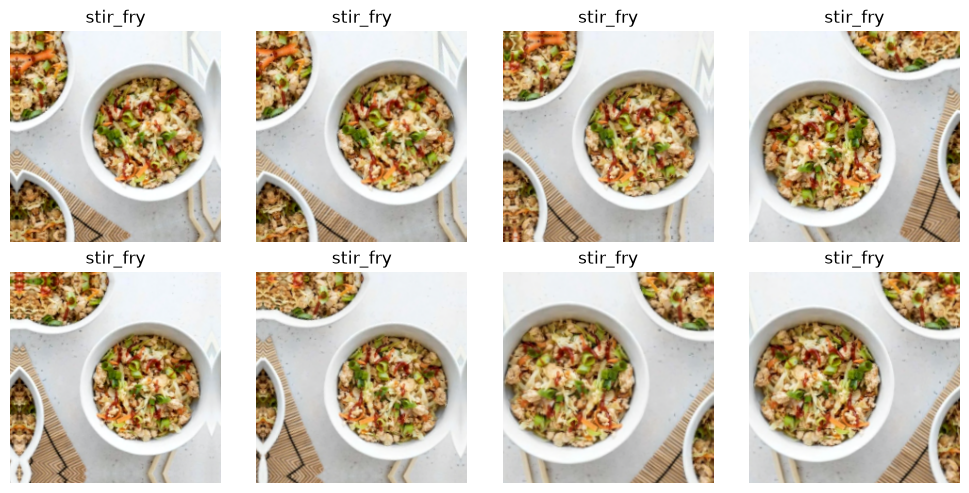

In [6]:
augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05),  # fraction of a full turn: 0.05 is 18 degrees
    layers.RandomZoom(0.1),
    layers.RandomContrast(0.1),
], name="augmentation")

show_images(
    [augmentation(images[:1], training=True)[0] for _ in range(8)],
    [CLASS_NAMES[labels[0]]] * 8,
)

### 3.2 Training

`train` compiles and fits a model with the same settings for every model.

- **Loss:** sparse categorical cross entropy on logits. Labels are integers, and every model ends in `Dense(6)` with no activation.
- **Optimizer:** Adam with a default learning rate of 0.001.
- **Class weights** from section 2.3.
- **Early stopping** on validation loss with a patience of 5 epochs. It restores the weights from the best epoch, so the returned model is the best one seen and not the last.

`plot_curves` draws training and validation accuracy and loss. The dotted line marks the epoch with the lowest validation loss, which is the epoch early stopping keeps.

In [7]:
def train(model, epochs=30, learning_rate=1e-3, patience=5):
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate),
        loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
        metrics=["accuracy"],
    )
    early_stop = tf.keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=patience, restore_best_weights=True
    )
    return model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=epochs,
        class_weight=class_weight,
        shuffle=False,  # train_ds is already shuffled in load()
        callbacks=[early_stop],
    )


def plot_curves(history, title):
    h = history.history
    epochs = range(1, len(h["loss"]) + 1)
    best_epoch = int(np.argmin(h["val_loss"])) + 1

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for ax, metric in zip(axes, ["accuracy", "loss"]):
        ax.plot(epochs, h[metric], label="train")
        ax.plot(epochs, h[f"val_{metric}"], label="validation")
        ax.axvline(best_epoch, color="grey", linestyle=":", label=f"best epoch ({best_epoch})")
        ax.set(title=metric.capitalize(), xlabel="Epoch")
        ax.legend()
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

### 3.3 Evaluation

`evaluate` runs once per model on the test set and reports:

- accuracy and macro F1
- precision, recall and F1 per class
- a confusion matrix
- accuracy per source site

The site table checks for a shortcut. Site and class overlap in this dataset: sugarspunrun supplies about half of cake and cookies, and omnivorescookbook supplies most of stir fry. A model can score well by recognising a blog's photo style instead of the food. A large gap in accuracy between sites points to that.

Each result goes into `results` for the comparison in section 6.

In [8]:
site_of = pd.read_csv(ROOT / "data" / "split.csv").set_index("filename")["source_site"]
results = {}


def evaluate(model, ds, files, title):
    y_true = np.concatenate([y for _, y in ds])
    y_pred = model.predict(ds, verbose=0).argmax(axis=1)

    acc = accuracy_score(y_true, y_pred)
    macro_f1 = f1_score(y_true, y_pred, average="macro")
    print(f"{title}: accuracy {acc:.3f}, macro F1 {macro_f1:.3f}\n")
    print(classification_report(y_true, y_pred, target_names=CLASS_NAMES, digits=3, zero_division=0))

    ConfusionMatrixDisplay.from_predictions(
        y_true, y_pred, display_labels=CLASS_NAMES, xticks_rotation=45, cmap="Blues", colorbar=False
    )
    plt.title(title)
    plt.show()

    per_site = (
        pd.DataFrame({"site": site_of[[Path(f).name for f in files]].values, "correct": y_true == y_pred})
        .groupby("site")["correct"]
        .agg(accuracy="mean", images="size")
        .sort_values("accuracy")
    )
    display(per_site.round(3))

    return {"accuracy": acc, "macro F1": macro_f1, "parameters": model.count_params()}

## 4. Model 1: CNN from scratch

In [9]:
tf.keras.utils.set_random_seed(SEED)

cnn_baseline = tf.keras.models.Sequential([
    tf.keras.Input(shape=INPUT_SHAPE),
    layers.Rescaling(1 / 255),
    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D(),
    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D(),
    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.MaxPooling2D(),
    layers.Conv2D(256, (3, 3), activation="relu"),
    layers.MaxPooling2D(),
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.5),
    layers.Dense(NUM_CLASSES),
], name="cnn_baseline")

In [10]:
history_baseline = train(cnn_baseline)

Epoch 1/30
37/37 ━━━━━━━━━━━━━━━━━━━━ 12s 307ms/step - accuracy: 0.2102 - loss: 1.7402 - val_accuracy: 0.2937 - val_loss: 1.6165
Epoch 2/30
37/37 ━━━━━━━━━━━━━━━━━━━━ 12s 311ms/step - accuracy: 0.2996 - loss: 1.5794 - val_accuracy: 0.3254 - val_loss: 1.5593
Epoch 3/30
37/37 ━━━━━━━━━━━━━━━━━━━━ 12s 315ms/step - accuracy: 0.3345 - loss: 1.4967 - val_accuracy: 0.3373 - val_loss: 1.6256
Epoch 4/30
37/37 ━━━━━━━━━━━━━━━━━━━━ 12s 317ms/step - accuracy: 0.3413 - loss: 1.5154 - val_accuracy: 0.3651 - val_loss: 1.4664
Epoch 5/30
37/37 ━━━━━━━━━━━━━━━━━━━━ 12s 325ms/step - accuracy: 0.4034 - loss: 1.3834 - val_accuracy: 0.4484 - val_loss: 1.3851
Epoch 6/30
37/37 ━━━━━━━━━━━━━━━━━━━━ 12s 325ms/step - accuracy: 0.4383 - loss: 1.3410 - val_accuracy: 0.3730 - val_loss: 1.4076
Epoch 7/30
37/37 ━━━━━━━━━━━━━━━━━━━━ 12s 332ms/step - accuracy: 0.4077 - loss: 1.3571 - val_accuracy: 0.4087 - val_loss: 1.3644
Epoch 8/30
37/37 ━━━━━━━━━━━━━━━━━━━━ 12s 332ms/step - accuracy: 0.4374 - loss: 1.3173 - val_accu

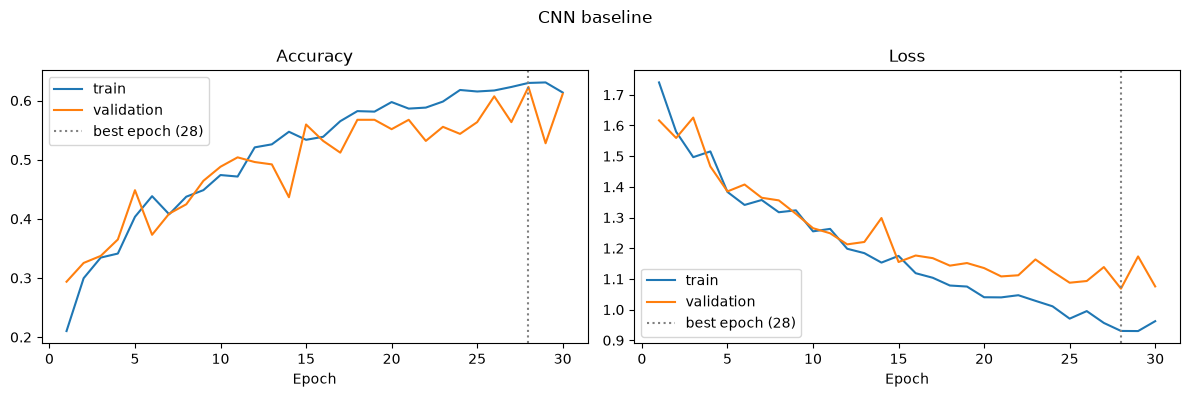

In [11]:
plot_curves(history_baseline, "CNN baseline")

### Baseline results

| | Epoch 1 | Epoch 15 | Epoch 30 |
| --- | --- | --- | --- |
| Train accuracy | 0.21 | 0.53 | 0.61 |
| Val accuracy | 0.29 | 0.56 | 0.61 |
| Val loss | 1.62 | 1.16 | 1.08 |

The graph and table above show that the model is still learning, but it slows down over time. Training ran for all 30 epochs because it hit the epoch limit, and the best weights came from epoch 28. The next step is to train the exact same model with a much larger number of epochs, and analyze what the curves look like.

In [12]:
tf.keras.utils.set_random_seed(SEED)

model_1 = tf.keras.models.Sequential([
    tf.keras.Input(shape=INPUT_SHAPE),
        layers.Rescaling(1 / 255),
        layers.Conv2D(32, (3, 3), activation="relu"),
        layers.MaxPooling2D(),
        layers.Conv2D(64, (3, 3), activation="relu"),
        layers.MaxPooling2D(),
        layers.Conv2D(128, (3, 3), activation="relu"),
        layers.MaxPooling2D(),
        layers.Conv2D(256, (3, 3), activation="relu"),
        layers.MaxPooling2D(),
        layers.GlobalAveragePooling2D(),
        layers.Dropout(0.5),
        layers.Dense(NUM_CLASSES),
], name="model_1")

In [13]:
history_model_1 = train(model_1, epochs=80, patience=8)

Epoch 1/80
37/37 ━━━━━━━━━━━━━━━━━━━━ 15s 380ms/step - accuracy: 0.2213 - loss: 1.7386 - val_accuracy: 0.2421 - val_loss: 1.6599
Epoch 2/80
37/37 ━━━━━━━━━━━━━━━━━━━━ 14s 375ms/step - accuracy: 0.3157 - loss: 1.5583 - val_accuracy: 0.2976 - val_loss: 1.5202
Epoch 3/80
37/37 ━━━━━━━━━━━━━━━━━━━━ 14s 376ms/step - accuracy: 0.3379 - loss: 1.5120 - val_accuracy: 0.4127 - val_loss: 1.4756
Epoch 4/80
37/37 ━━━━━━━━━━━━━━━━━━━━ 14s 370ms/step - accuracy: 0.3770 - loss: 1.4544 - val_accuracy: 0.3214 - val_loss: 1.4864
Epoch 5/80
37/37 ━━━━━━━━━━━━━━━━━━━━ 16s 424ms/step - accuracy: 0.3711 - loss: 1.4757 - val_accuracy: 0.3135 - val_loss: 1.4642
Epoch 6/80
37/37 ━━━━━━━━━━━━━━━━━━━━ 15s 409ms/step - accuracy: 0.4196 - loss: 1.3771 - val_accuracy: 0.3690 - val_loss: 1.4211
Epoch 7/80
37/37 ━━━━━━━━━━━━━━━━━━━━ 15s 411ms/step - accuracy: 0.4204 - loss: 1.3482 - val_accuracy: 0.4444 - val_loss: 1.3237
Epoch 8/80
37/37 ━━━━━━━━━━━━━━━━━━━━ 16s 422ms/step - accuracy: 0.4349 - loss: 1.3004 - val_accu

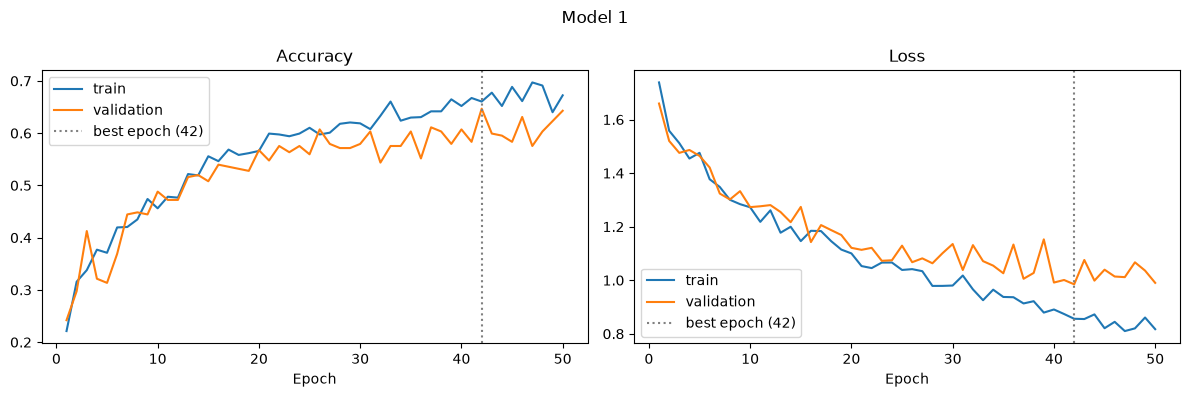

In [15]:
plot_curves(history_model_1, "Model 1")

# Model 1 Results

Looking at the graph above, training stopped at the 50th epoch, and the 42nd was the best. This is the limit of these settings. A small gap between training and validation also starts to open after epoch 40, so the model is starting to memorise. But the main problem is still the slow and unsteady learning, so adding Batch Normalization is the next improvement to try.

Lowering the learning rate would make training steadier but even slower, while Batch Normalization can fix both the slow and the unsteady learning, so I tried it first.

# Model 2

In [21]:
tf.keras.utils.set_random_seed(SEED)

model_1_bn = tf.keras.models.Sequential([
    tf.keras.Input(shape=INPUT_SHAPE),
        layers.Rescaling(1 / 255),
        layers.Conv2D(32, (3, 3)),
        layers.BatchNormalization(momentum=0.9),
        layers.ReLU(),
        layers.MaxPooling2D(),
        layers.Conv2D(64, (3, 3)),
        layers.BatchNormalization(momentum=0.9),
        layers.ReLU(),
        layers.MaxPooling2D(),
        layers.Conv2D(128, (3, 3)),
        layers.BatchNormalization(momentum=0.9),
        layers.ReLU(),
        layers.MaxPooling2D(),
        layers.Conv2D(256, (3, 3)),
        layers.BatchNormalization(momentum=0.9),
        layers.ReLU(),
        layers.MaxPooling2D(),
        layers.GlobalAveragePooling2D(),
        layers.Dropout(0.5),
        layers.Dense(NUM_CLASSES),
], name="model_1_bn")

In [22]:
history_model_1_bn = train(model_1_bn, epochs=80, patience=8)

Epoch 1/80
37/37 ━━━━━━━━━━━━━━━━━━━━ 18s 453ms/step - accuracy: 0.3702 - loss: 1.7568 - val_accuracy: 0.1865 - val_loss: 2.0932
Epoch 2/80
37/37 ━━━━━━━━━━━━━━━━━━━━ 17s 464ms/step - accuracy: 0.4417 - loss: 1.4692 - val_accuracy: 0.3135 - val_loss: 1.9695
Epoch 3/80
37/37 ━━━━━━━━━━━━━━━━━━━━ 18s 478ms/step - accuracy: 0.4647 - loss: 1.3628 - val_accuracy: 0.4563 - val_loss: 1.3749
Epoch 4/80
37/37 ━━━━━━━━━━━━━━━━━━━━ 18s 484ms/step - accuracy: 0.4928 - loss: 1.2883 - val_accuracy: 0.5040 - val_loss: 1.2823
Epoch 5/80
37/37 ━━━━━━━━━━━━━━━━━━━━ 18s 490ms/step - accuracy: 0.5081 - loss: 1.2640 - val_accuracy: 0.5516 - val_loss: 1.1949
Epoch 6/80
37/37 ━━━━━━━━━━━━━━━━━━━━ 19s 512ms/step - accuracy: 0.5472 - loss: 1.1920 - val_accuracy: 0.5040 - val_loss: 1.2333
Epoch 7/80
37/37 ━━━━━━━━━━━━━━━━━━━━ 19s 517ms/step - accuracy: 0.5651 - loss: 1.1640 - val_accuracy: 0.5476 - val_loss: 1.1278
Epoch 8/80
37/37 ━━━━━━━━━━━━━━━━━━━━ 19s 512ms/step - accuracy: 0.5643 - loss: 1.1116 - val_accu

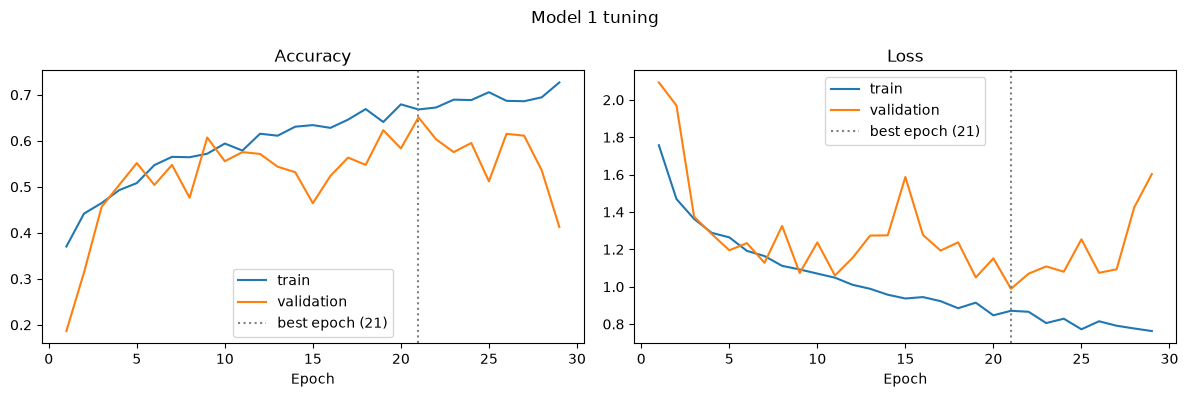

In [23]:
plot_curves(history_model_1_bn, "Model 1 tuning")

# Interpretation

The graph above shows that the model is learning much faster, but the performance is more or less the same. Training stopped at the 29th epoch, and the 21st was the best. It's still jumpy even though the learning is faster, and the gap between training and validation opens earlier than before.

| | Model 1 | Model 1 + BatchNorm |
| --- | --- | --- |
| Best epoch | 42 | 21 |
| Stopped at | 50 | 29 |
| Best val loss | 0.985 | 0.989 |
| Val accuracy (best epoch) | 0.647 | 0.651 |
| Val accuracy at epoch 5 | 0.31 | 0.55 |
| Train accuracy (final epoch) | 0.67 | 0.73 |

The model now hits the same limit faster, and the gap between training and validation shows it's starting to memorise the training photos. Augmentation targets that directly, because the model sees a slightly different version of each photo every epoch and has to learn the food instead of the exact images. This should improve generalisation, meaning how well it does on photos it hasn't seen. A learning rate schedule would mostly smooth out the jumpiness without raising the best score, and a bigger model would only give it more room to memorise, so I tried augmentation next.

# Model 2

In [24]:
tf.keras.utils.set_random_seed(SEED)

model_2 = tf.keras.models.Sequential([
    tf.keras.Input(shape=INPUT_SHAPE),
        augmentation,
        layers.Rescaling(1 / 255),
        layers.Conv2D(32, (3, 3)),
        layers.BatchNormalization(momentum=0.9),
        layers.ReLU(),
        layers.MaxPooling2D(),
        layers.Conv2D(64, (3, 3)),
        layers.BatchNormalization(momentum=0.9),
        layers.ReLU(),
        layers.MaxPooling2D(),
        layers.Conv2D(128, (3, 3)),
        layers.BatchNormalization(momentum=0.9),
        layers.ReLU(),
        layers.MaxPooling2D(),
        layers.Conv2D(256, (3, 3)),
        layers.BatchNormalization(momentum=0.9),
        layers.ReLU(),
        layers.MaxPooling2D(),
        layers.GlobalAveragePooling2D(),
        layers.Dropout(0.5),
        layers.Dense(NUM_CLASSES),
], name="model2")

In [25]:
history_model_2 = train(model_2, epochs=80, patience=8)

Epoch 1/80
37/37 ━━━━━━━━━━━━━━━━━━━━ 19s 469ms/step - accuracy: 0.3617 - loss: 1.7121 - val_accuracy: 0.2143 - val_loss: 2.0237
Epoch 2/80
37/37 ━━━━━━━━━━━━━━━━━━━━ 17s 468ms/step - accuracy: 0.4417 - loss: 1.4543 - val_accuracy: 0.4405 - val_loss: 1.5663
Epoch 3/80
37/37 ━━━━━━━━━━━━━━━━━━━━ 18s 475ms/step - accuracy: 0.4766 - loss: 1.3600 - val_accuracy: 0.4087 - val_loss: 1.6344
Epoch 4/80
37/37 ━━━━━━━━━━━━━━━━━━━━ 18s 478ms/step - accuracy: 0.5098 - loss: 1.2982 - val_accuracy: 0.4563 - val_loss: 1.3561
Epoch 5/80
37/37 ━━━━━━━━━━━━━━━━━━━━ 18s 483ms/step - accuracy: 0.5268 - loss: 1.2328 - val_accuracy: 0.4167 - val_loss: 1.5244
Epoch 6/80
37/37 ━━━━━━━━━━━━━━━━━━━━ 18s 490ms/step - accuracy: 0.5336 - loss: 1.2204 - val_accuracy: 0.3889 - val_loss: 1.6433
Epoch 7/80
37/37 ━━━━━━━━━━━━━━━━━━━━ 18s 495ms/step - accuracy: 0.5362 - loss: 1.1830 - val_accuracy: 0.4127 - val_loss: 1.7922
Epoch 8/80
37/37 ━━━━━━━━━━━━━━━━━━━━ 18s 492ms/step - accuracy: 0.5489 - loss: 1.1419 - val_accu

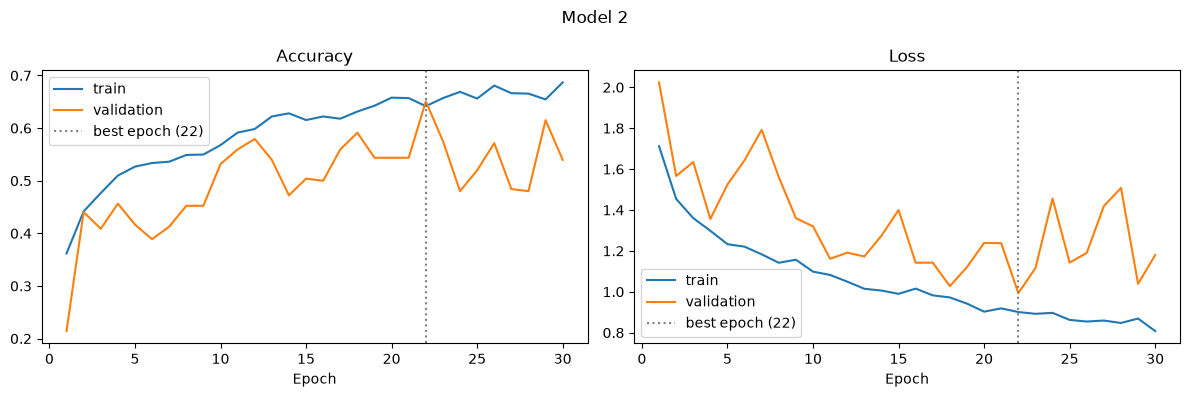

In [27]:
plot_curves(history_model_2, "Model 2")

# Interpretation

The graph above shows that it takes longer to learn. Training stopped at the 30th epoch, and the 22nd was the best. The accuracy and loss are about the same as the other two, and validation is even jumpier. All three versions end up around 65% validation accuracy, which shows the limit of training from scratch on this dataset. So I chose the one with the lowest validation loss, Model 1, as the final model.

| | Model 1 | + BatchNorm | + BatchNorm + Augmentation |
| --- | --- | --- | --- |
| Best epoch | 42 | 21 | 22 |
| Best val loss | 0.985 | 0.989 | 0.993 |
| Val accuracy | 0.647 | 0.651 | 0.651 |
| Train accuracy (final) | 0.67 | 0.73 | 0.69 |

# Evaluation

Model 1: accuracy 0.643, macro F1 0.639

              precision    recall  f1-score   support

        cake      0.557     0.756     0.642        45
     cookies      0.700     0.488     0.575        43
       pasta      0.600     0.419     0.493        43
       salad      0.717     0.733     0.725        45
        soup      0.667     0.667     0.667        45
    stir_fry      0.650     0.839     0.732        31

    accuracy                          0.643       252
   macro avg      0.649     0.650     0.639       252
weighted avg      0.648     0.643     0.636       252



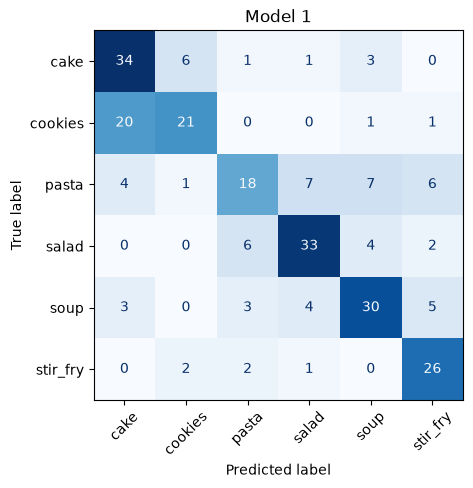

,accuracy,images
site,,
natashaskitchen.com,0.000,5
loveandlemons.com,0.531,32
budgetbytes.com,0.578,64
recipetineats.com,0.672,61
sugarspunrun.com,0.705,44
omnivorescookbook.com,0.769,26
cafedelites.com,0.800,20


In [28]:
results["Model 1"] = evaluate(model_1, test_ds, test_files, "Model 1")

# Interpretation

Model 1 scored 64.3% accuracy and a macro F1 of 0.639 on the test set, which is almost the same as validation (64.7%). So the tuning didn't overfit the validation set, and this is the model's real performance.

The confusion matrix shows the biggest mistake is cookies being predicted as cake (20 of 43 cookies). They're both baked and brown, and most of them come from the same site. Pasta is the weakest class because its mistakes are spread across salad, soup and stir fry, which makes sense since pasta shows up in all of those dishes. Stir fry did the best even though it has the fewest images.

The sites that supply most of one class, omnivorescookbook for stir fry and sugarspunrun for cake and cookies, score above average. This could mean the model is using the site's photo style as a shortcut, but the test set is too small per site to confirm it.

## 5. Model 2: transfer learning

_To do._

## 6. Comparison

Architecture, hyperparameters, training curves and test results side by side.

In [14]:
pd.DataFrame(results).T.astype({"parameters": int}).round(3)

KeyError: "Only a column name can be used for the key in a dtype mappings argument. 'parameters' not found in columns."

## 7. Use of generative AI

_Running notes for item 5. Rewrite in your own words._

- Claude helped design the data loader, the class weight formula and the augmentation block.
- Claude reviewed the first Model 0 cells and pointed out a rescaling typo (1/225), a model rebuilt after compiling, and a Keras F1 metric that does not work with integer labels.
- Claude restructured this notebook into shared functions and sections.